# EDA: качество рентгеновских снимков

**Цель:** познакомиться с COVID-19 Radiography Database и выяснить, что потребуется
для исследования артефактов: пропуски, баланс диагнозов, технические проблемы и
необычные изображения. Одна запись в основной таблице - один снимок; маски считаем отдельно.

In [2]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageEnhance, ImageFilter
from IPython.display import display

SEED = 42
CLASSES = ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Откройте ноутбук из папки проекта с pyproject.toml.')
folders = sorted(p.parent for p in (ROOT/'data/raw').rglob('COVID') if (p/'images').is_dir())
if len(folders) != 1:
    raise ValueError(f'Нужна одна распакованная копия датасета в data/raw; найдено {len(folders)}.')
DATA = folders[0]
REPORTS = ROOT/'reports/tables'
REPORTS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')


## 2. Собираем таблицу снимков и проверяем чтение файлов

Ниже одна вспомогательная функция: она читает размер, формат и режим изображения.
Для снимков дополнительно вычисляет среднюю яркость и контраст (стандартное отклонение
яркости), а также SHA-256 для поиска точных копий файлов. 

Яркость и контраст считаем на шкале 0…255 для режимов L/RGB; другие режимы сохраняем
в таблице, но не переводим в 8 бит. Маски проверяем отдельно. Файлы с неожиданным
расширением показываем списком, но не вычитаем из количества прочитанных снимков.


In [3]:
def read_image_info(path, calculate_metrics=False):
    info = dict(width=np.nan, height=np.nan, mode=None, format=None,
                brightness=np.nan, contrast=np.nan, sha256=None, error=None)
    try:
        with Image.open(path) as image:
            image.load()
            info.update(width=image.width, height=image.height, mode=image.mode, format=image.format)
            if calculate_metrics and image.mode in {'L', 'RGB'}:
                pixels = np.asarray(image.convert('L'), dtype=np.float32)
                info.update(brightness=float(pixels.mean()), contrast=float(pixels.std()))
        if calculate_metrics:
            with path.open('rb') as file:
                info['sha256'] = hashlib.file_digest(file, 'sha256').hexdigest()
    except (OSError, ValueError, SyntaxError) as error:
        info['error'] = str(error)
    return info

records, unexpected_files = [], []
for label in CLASSES:
    if not (DATA/label/'images').is_dir():
        raise FileNotFoundError(DATA/label/'images')
    for kind in ['images', 'masks']:
        for path in sorted((DATA/label/kind).glob('*')):
            if not path.is_file():
                continue
            if path.suffix.lower() not in {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}:
                unexpected_files.append(path.relative_to(DATA).as_posix())
                continue
            records.append(dict(image_id=f'{label}/{path.name}', label=label, kind=kind,
                                path=path.relative_to(ROOT).as_posix(),
                                **read_image_info(path, calculate_metrics=kind=='images')))
    print('Проверен класс:', label)

files = pd.DataFrame(records)
if files.empty:
    raise ValueError('В папках images и masks нет файлов изображений.')
df = files[files.kind.eq('images')].set_index('image_id').copy()
masks = files[files.kind.eq('masks')].set_index('image_id').copy()
if df.empty:
    raise ValueError('Файлы снимков не найдены.')
df = df.join(masks[['path','error','width','height']].add_prefix('mask_'), how='left')
df['mask_missing'] = df.mask_path.isna()
df['mask_size_mismatch'] = (df.width.notna() & df.mask_width.notna()
                           & ((df.width != df.mask_width) | (df.height != df.mask_height)))
good = df[df.error.isna()].copy()
print('Снимков:', len(df), '| Масок:', len(masks), '| Неожиданных файлов:', len(unexpected_files))
print('Неожиданные файлы, первые 10:', unexpected_files[:10])
display(df.head())


Проверен класс: COVID
Проверен класс: Lung_Opacity
Проверен класс: Normal
Проверен класс: Viral Pneumonia
Снимков: 21165 | Масок: 21165 | Неожиданных файлов: 0
Неожиданные файлы, первые 10: []


,label,kind,path,width,height,mode,format,brightness,contrast,sha256,error,mask_path,mask_error,mask_width,mask_height,mask_missing,mask_size_mismatch
image_id,,,,,,,,,,,,,,,,,
COVID/COVID-1.png,COVID,images,data/raw/COVID-19_Radiography_Dataset/COVID/im...,299,299,L,PNG,145.896851,51.816635,cee641860c5fbc230bf8f7d19b2acf2f4de013dbacca44...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,256,256,False,True
COVID/COVID-10.png,COVID,images,data/raw/COVID-19_Radiography_Dataset/COVID/im...,299,299,L,PNG,141.355469,40.623287,cb90c13f9d12709c5470652e7077472c4ffdb273b2b0a5...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,256,256,False,True
COVID/COVID-100.png,COVID,images,data/raw/COVID-19_Radiography_Dataset/COVID/im...,299,299,L,PNG,152.878571,73.778046,f9852c02363c1953a2cab875ac6770ebe55ac9befd8b1d...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,256,256,False,True
COVID/COVID-1000.png,COVID,images,data/raw/COVID-19_Radiography_Dataset/COVID/im...,299,299,L,PNG,162.771057,76.249130,6c429f8661936f9aebb7ad1db1c9a6776c215181ceef0e...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,256,256,False,True
COVID/COVID-1001.png,COVID,images,data/raw/COVID-19_Radiography_Dataset/COVID/im...,299,299,L,PNG,129.890778,66.179558,24fc6b3846a4b00f8aa5cc194d271b4a74a38a32f969e5...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,256,256,False,True


В датасете обнаружено 21 165 рентгеновских снимков и 21 165 масок лёгких. 
Но их равенство само по себе ещё не доказывает правильность всех пар. 
Файлов с неожиданными расширениями нет. 
Основная таблица содержит по одной строке на снимок: его класс, путь, размер, формат, яркость, контраст и сведения о соответствующей маске.

Снимки имеют разрешение 299×299 пикселей, а маски — 256×256. Следовательно, перед совместным использованием снимков и масок необходимо проверить и согласовать их размеры. 

## 3. Баланс классов

Считаем количество и долю **снимков** каждого класса.


,images,readable,share_pct
label,,,
COVID,3616,3616,17.08
Lung_Opacity,6012,6012,28.41
Normal,10192,10192,48.15
Viral Pneumonia,1345,1345,6.35


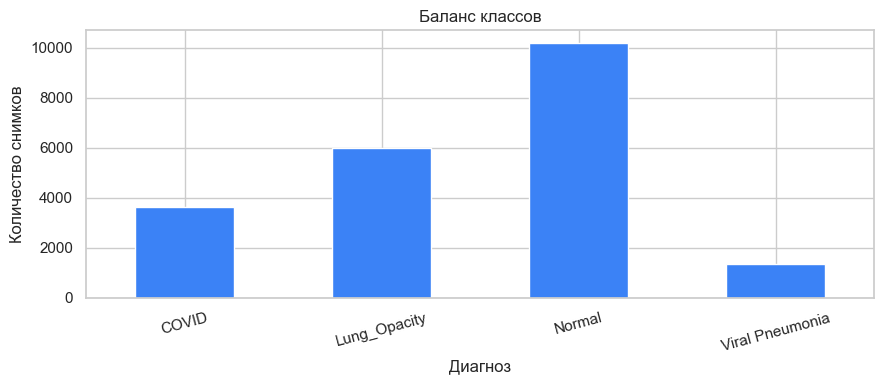

Отношение крупнейшего класса к наименьшему непустому: 7.58


In [4]:
balance = df.groupby('label').agg(images=('path','size'), readable=('error',lambda x: x.isna().sum()))
balance = balance.reindex(CLASSES, fill_value=0)
balance['share_pct'] = (100*balance.images/balance.images.sum()).round(2)
display(balance)
balance.images.plot.bar(figsize=(9,4), color='#3b82f6', rot=15)
plt.ylabel('Количество снимков'); plt.xlabel('Диагноз'); plt.title('Баланс классов')
plt.tight_layout(); plt.show()
nonempty = balance.loc[balance.images.gt(0), 'images']
print('Отношение крупнейшего класса к наименьшему непустому:', round(nonempty.max()/nonempty.min(), 2))


Распределение снимков по классам неравномерно:
крупнейший класс Normal превышает наименьший класс Viral Pneumonia в 7,58 раза. 
При последующем обучении модели нужно будет учесть дисбаланс классов.


## 4. Пропуски и технические ошибки

Для изображений пропуск — это, например, отсутствующая маска или недоступная метрика.
Нулевой пиксель означает чёрный цвет и сам по себе не является пропуском.


In [5]:
issues = pd.Series({
    'Не удалось прочитать снимок': int(df.error.notna().sum()),
    'Не удалось прочитать маску': int(masks.error.notna().sum()),
    'У снимка нет маски с тем же именем': int(df.mask_missing.sum()),
    'Размер маски отличается от снимка': int(df.mask_size_mismatch.sum()),
    'Маска без снимка с тем же именем': int((~masks.index.isin(df.index)).sum()),
})
display(issues.to_frame('count'))
features = ['width','height','brightness','contrast']
missing = pd.DataFrame({'count':df[features].isna().sum(), 'percent':100*df[features].isna().mean()})
display(missing)
display(df.groupby('label').mask_missing.agg(['sum','mean']).rename(columns={'sum':'missing_masks','mean':'fraction'}))
print('Доля пропусков среди четырёх численных признаков:', f'{df[features].isna().to_numpy().mean():.2%}')
print('Читаемых снимков с режимом вне L/RGB:', int((~good['mode'].isin(['L','RGB'])).sum()))
display(df.loc[df.error.notna() | df.mask_missing | df.mask_error.notna() | df.mask_size_mismatch,
               ['label','path','error','mask_path','mask_error','mask_missing','mask_size_mismatch']].head(10))


,count
Не удалось прочитать снимок,0
Не удалось прочитать маску,0
У снимка нет маски с тем же именем,0
Размер маски отличается от снимка,21165
Маска без снимка с тем же именем,0


,count,percent
width,0,0.0
height,0,0.0
brightness,0,0.0
contrast,0,0.0


,missing_masks,fraction
label,,
COVID,0,0.0
Lung_Opacity,0,0.0
Normal,0,0.0
Viral Pneumonia,0,0.0


Доля пропусков среди четырёх численных признаков: 0.00%
Читаемых снимков с режимом вне L/RGB: 0


,label,path,error,mask_path,mask_error,mask_missing,mask_size_mismatch
image_id,,,,,,,
COVID/COVID-1.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,False,True
COVID/COVID-10.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,False,True
COVID/COVID-100.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,False,True
COVID/COVID-1000.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,False,True
COVID/COVID-1001.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,False,True
COVID/COVID-1002.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,False,True
COVID/COVID-1003.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,False,True
COVID/COVID-1004.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,False,True
COVID/COVID-1005.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,None,data/raw/COVID-19_Radiography_Dataset/COVID/ma...,None,False,True


Отсутствующих пар «снимок — маска» и масок без снимка не обнаружено. В признаках width, height, brightness и contrast пропусков нет, все снимки представлены в режимах L или RGB, для которых были рассчитаны яркость и контраст.
Заполнение пропусков для проверенных численных признаков не требуется.


## 5. Метаданные: количество строк и пропуски

Читаем четыре стандартные таблицы `*.metadata.xlsx`.
Сравниваем число строк с числом файлов и явно показываем пропуски. 


In [ ]:
metadata_tables, metadata_counts = [], {}
for label in CLASSES:
    path = DATA/f'{label}.metadata.xlsx'
    if not path.exists():
        print('Нет таблицы:', path.name)
        continue
    table = pd.read_excel(path, engine='openpyxl').replace(r'^\s*$', np.nan, regex=True)
    table.columns = table.columns.str.strip()
    metadata_counts[label] = len(table)
    metadata_tables.append(table.assign(label=label))
display(balance[['images']].join(pd.Series(metadata_counts, name='metadata_rows')))
if metadata_tables:
    meta = pd.concat(metadata_tables, ignore_index=True)
    display(meta.head())
    display(pd.DataFrame({'missing_count':meta.isna().sum(), 'missing_pct':100*meta.isna().mean()}))
    display(meta.describe(include='all').T)
    if 'URL' in meta:
        display(meta.groupby('label').URL.nunique().rename('unique_source_urls').to_frame())
else:
    print('Таблиц метаданных нет, статистики снимков выше остаются доступны.')


,images,metadata_rows
label,,
COVID,3616,3616
Lung_Opacity,6012,6012
Normal,10192,10192
Viral Pneumonia,1345,1345


,FILE NAME,FORMAT,SIZE,URL,label
0,COVID-1,PNG,256*256,https://sirm.org/category/senza-categoria/covi...,COVID
1,COVID-2,PNG,256*256,https://sirm.org/category/senza-categoria/covi...,COVID
2,COVID-3,PNG,256*256,https://sirm.org/category/senza-categoria/covi...,COVID
3,COVID-4,PNG,256*256,https://sirm.org/category/senza-categoria/covi...,COVID
4,COVID-5,PNG,256*256,https://sirm.org/category/senza-categoria/covi...,COVID


,missing_count,missing_pct
FILE NAME,0,0.0
FORMAT,0,0.0
SIZE,0,0.0
URL,0,0.0
label,0,0.0


,count,unique,top,freq
FILE NAME,21165,21165,Viral Pneumonia-1345,1
FORMAT,21165,1,PNG,21165
SIZE,21165,1,256*256,21165
URL,21165,8,https://www.kaggle.com/c/rsna-pneumonia-detect...,14863
label,21165,4,Normal,10192


,unique_source_urls
label,
COVID,6
Lung_Opacity,1
Normal,2
Viral Pneumonia,1


Для каждого класса количество строк метаданных совпадает с количеством снимков. В полях FILE NAME, FORMAT, SIZE, URL и добавленном поле label пропусков не обнаружено. Все значения FILE NAME уникальны.

## 6. Размеры, форматы, яркость и контраст

Размеры и форматы берём из самих файлов. Яркость — среднее значение пикселей,
контраст — их стандартное отклонение. 


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
width,21165.0,NaN,NaN,NaN,299.0,0.0,299.0,299.0,299.0,299.0,299.0
height,21165.0,NaN,NaN,NaN,299.0,0.0,299.0,299.0,299.0,299.0,299.0
brightness,21165.0,NaN,NaN,NaN,129.908506,23.491756,25.511381,113.313187,127.133888,146.682907,229.141693
contrast,21165.0,NaN,NaN,NaN,59.017312,11.104801,14.145251,51.657093,60.10421,67.152954,106.99868
label,21165,4,Normal,10192,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mode,21165,2,L,21025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
format,21165,1,PNG,21165,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,,images
width,height,
299,299,21165


format,PNG
label,
COVID,3616
Lung_Opacity,6012
Normal,10192
Viral Pneumonia,1345


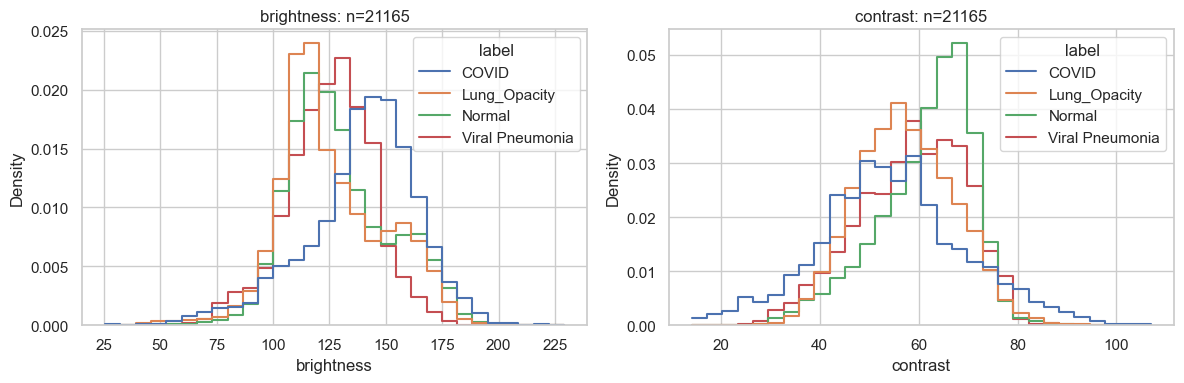

brightness                                    contrast  \
                     count        mean      median        std    count   
label                                                                    
COVID                 3616  139.521210  142.594757  25.029784     3616   
Lung_Opacity          6012  126.021596  120.819546  23.570601     6012   
Normal               10192  129.389800  125.509708  22.448670    10192   
Viral Pneumonia       1345  125.369630  126.860016  18.980974     1345   

                                                  
                      mean     median        std  
label                                             
COVID            54.647365  54.045332  14.829089  
Lung_Opacity     57.397085  56.967915   9.807737  
Normal           61.559355  63.533669   9.551679  
Viral Pneumonia  58.745215  59.706783  10.778896

In [7]:
display(good[features + ['label','mode','format']].describe(include='all').T)
display(good.groupby(['width','height']).size().sort_values(ascending=False).rename('images').to_frame())
display(pd.crosstab(good.label, good['format']))
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, column in zip(axes, ['brightness','contrast']):
    sns.histplot(data=good, x=column, hue='label', stat='density', common_norm=False,
                 element='step', fill=False, bins=30, ax=ax)
    ax.set_title(f'{column}: n={good[column].notna().sum()}')
plt.tight_layout(); plt.show()
display(good.groupby('label')[['brightness','contrast']].agg(['count','mean','median','std']))


В модели L представлены 21 025 снимков, остальные 140 — в RGB, что составляет около 0,66% датасета. 
При расчёте яркости и контраста RGB-изображения мы перевели в оттенки серого, поэтому показатели вычислялись единообразно.
Средняя яркость по датасету составляет 129,91, медиана — 127,13. Значения изменяются от 25,51 до 229,14 по шкале 0–255. Средний контраст составляет 59,02, медиана — 60,10; диапазон — от 14,15 до 107,00. Следовательно, при одинаковых размерах файлов их яркостные характеристики существенно различаются. 

В среднем снимки COVID наиболее светлые и имеют наименьший контраст. У Normal наблюдается наибольший средний контраст. При этом распределения классов существенно перекрываются: яркость и контраст не обеспечивают их однозначного разделения.

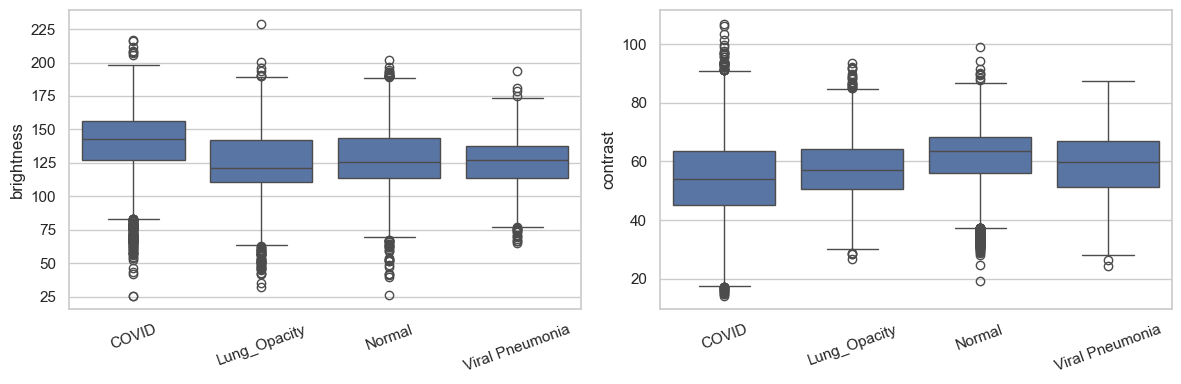

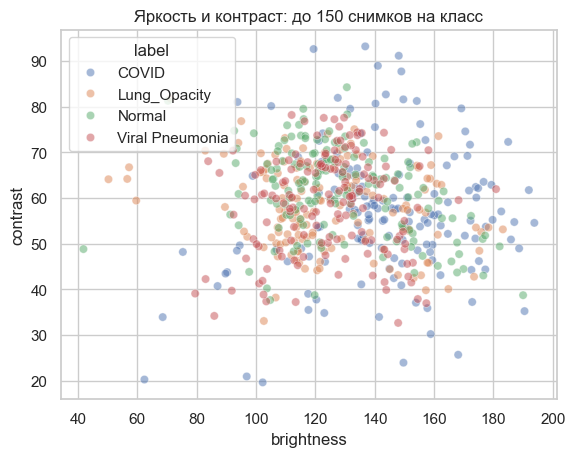

,brightness,contrast
brightness,1.000000,-0.149151
contrast,-0.149151,1.000000


In [8]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, column in zip(axes, ['brightness','contrast']):
    sns.boxplot(data=good, x='label', y=column, order=CLASSES, ax=ax)
    ax.tick_params(axis='x',rotation=20)
    ax.set_xlabel('')
plt.tight_layout(); plt.show()
plot_data = good.dropna(subset=['brightness','contrast'])
if not plot_data.empty:
    sample = pd.concat([g.sample(n=min(150,len(g)),random_state=SEED) for _,g in plot_data.groupby('label')])
    sns.scatterplot(data=sample, x='brightness', y='contrast', hue='label', alpha=.5)
    plt.title('Яркость и контраст: до 150 снимков на класс'); plt.show()
    display(plot_data[['brightness','contrast']].corr(method='spearman'))


Диаграммы размаха подтверждают различия типичных значений яркости и контраста между классами. У COVID медиана яркости выше, а медиана контраста ниже, чем у остальных классов. Разброс контраста у COVID также больше: его стандартное отклонение составляет 14,83 против примерно 9,55–10,78 у других классов.

На диаграммах присутствуют значения за пределами «усов». Они являются статистически необычными наблюдениями, но не автоматически ошибочными или непригодными снимками. Корреляция Спирмена между яркостью и контрастом составляет −0,149. Это слабая отрицательная монотонная связь: более высокая яркость лишь слабо связана с меньшим контрастом. 

На диаграмме рассеяния классы заметно перекрываются. Она построена по 150 случайным изображениям каждого класса — всего по 600 снимкам. Корреляция рассчитана по всем 21 165 снимкам.

## 7. Визуальный просмотр и необычные снимки

Сначала смотрим случайные примеры каждого класса с фиксированным seed. Затем смотрим
снимки с самым низким и высоким контрастом. Обращаем внимание на надписи, рамки, оборудование,
размытие и обрезанные области.

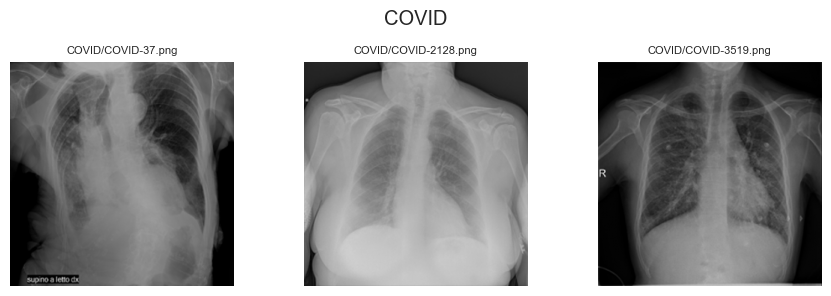

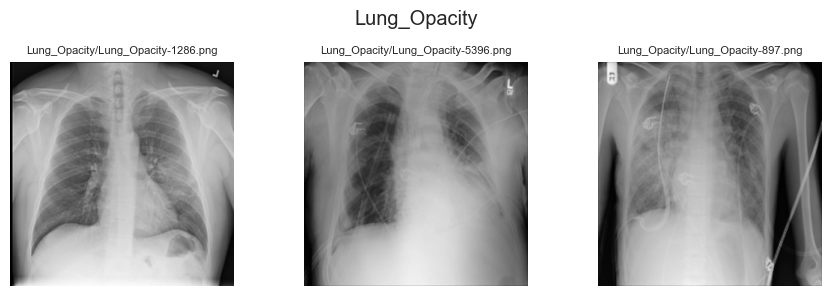

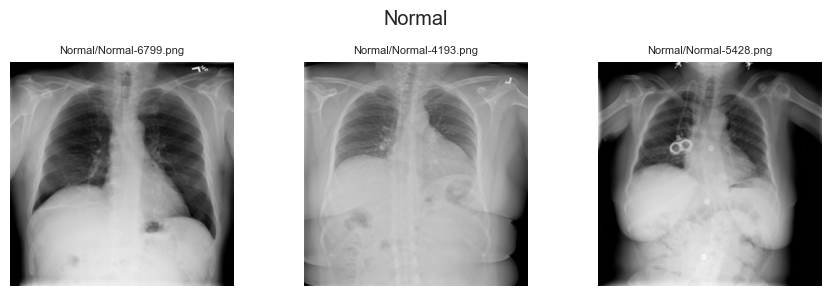

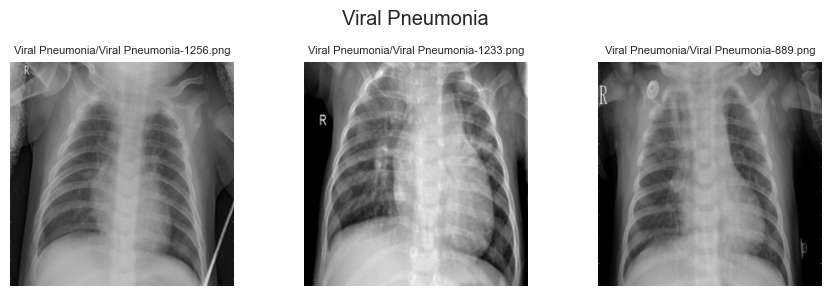

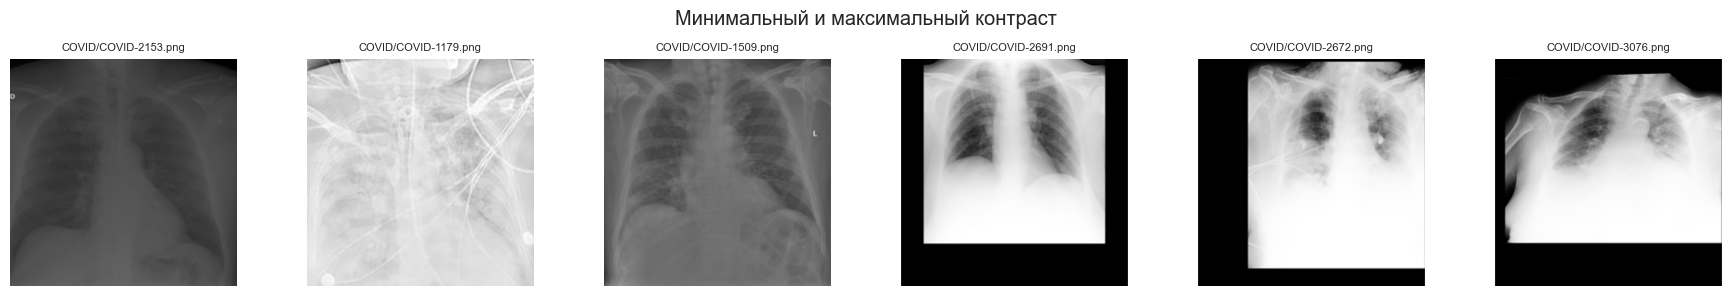

In [9]:
def show_images(frame, title):
    if frame.empty:
        print('Нет изображений для просмотра:', title)
        return
    fig, axes = plt.subplots(1,len(frame),figsize=(3*len(frame),3),squeeze=False)
    for ax, (image_id,row) in zip(axes.ravel(),frame.iterrows()):
        with Image.open(ROOT/row.path) as image:
            ax.imshow(image.convert('L'),cmap='gray',vmin=0,vmax=255)
        ax.set_title(image_id,fontsize=8); ax.axis('off')
    fig.suptitle(title); plt.tight_layout(); plt.show()

for label in CLASSES:
    group = good[good.label.eq(label) & good['mode'].isin(['L','RGB'])]
    show_images(group.sample(n=min(3,len(group)),random_state=SEED),label)
contrasts = good.dropna(subset=['contrast']).sort_values('contrast')
extremes = pd.concat([contrasts.head(3),contrasts.tail(3)])
show_images(extremes[~extremes.index.duplicated()], 'Минимальный и максимальный контраст')


При визуальном просмотре обнаружены различия в кадрировании, яркости, контрасте и наличии посторонних элементов. 
В группе низкого контраста встречаются как тёмные, так и светлые изображения: например, COVID-2153 выглядит тёмным, а COVID-1179 — очень светлым. Следовательно, низкий контраст не равнозначен низкой яркости.
Высокий глобальный контраст также не обязательно означает хорошую различимость полезных деталей. Его могут увеличивать чёрные рамки и большие светлые области. 
Показанные примеры подтверждают необходимость отдельной разметки надписей, маркеров, рамок и посторонних объектов. 

## 8. Точные дубликаты

SHA-256 выявляет одинаковые файлы. 
Считаем отдельно число файлов в повторяющихся группах и число лишних копий.


In [10]:
hashed = df.dropna(subset=['sha256'])
duplicates = hashed[hashed.duplicated('sha256',keep=False)]
print('Файлов в группах дубликатов:',len(duplicates))
print('Лишних копий сверх первой:',int(hashed.duplicated('sha256').sum()))
print('Групп с разными диагнозами:',int((duplicates.groupby('sha256').label.nunique()>1).sum()))
display(duplicates[['label','path','sha256']].head(10))


Файлов в группах дубликатов: 96
Лишних копий сверх первой: 54
Групп с разными диагнозами: 0


,label,path,sha256
image_id,,,
COVID/COVID-137.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,e436c2a3cf733557704633c5bb91adca220e7a3d73b4ab...
COVID/COVID-139.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,e436c2a3cf733557704633c5bb91adca220e7a3d73b4ab...
COVID/COVID-18.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,f49fb3b7facce5d8aca0742592264916f520992c125bd6...
COVID/COVID-2084.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,d96571cbe40c838d352659f522fd635bf8f07955c75e9c...
COVID/COVID-2085.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,d96571cbe40c838d352659f522fd635bf8f07955c75e9c...
COVID/COVID-21.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,f49fb3b7facce5d8aca0742592264916f520992c125bd6...
COVID/COVID-2416.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,71faccf4ae2bcab87ce58e3036f52a55cc15d3b76a73db...
COVID/COVID-2418.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,71faccf4ae2bcab87ce58e3036f52a55cc15d3b76a73db...
COVID/COVID-2420.png,COVID,data/raw/COVID-19_Radiography_Dataset/COVID/im...,17163011d42f04f3c7bc42c62f41dce27f0ef8c302a0c2...


Проверка SHA-256 выявила 96 файлов, входящих в группы точных дубликатов. Число лишних копий сверх первой составляет 54, или около 0,26% всех снимков. Эти результаты соответствуют 42 группам повторяющихся файлов.
После сохранения одной копии каждого уникального файла осталось бы 21 111 снимков. 
Среди найденных групп точных дубликатов нет групп с разными диагностическими метками. 

## 10. Сохраняем результаты и формулируем выводы

Таблицы помогут проверить расчёты и вернуться к проблемным файлам. Они сохраняются
в `reports/tables`; исходные снимки не меняются и автоматически не удаляются.


In [12]:
df.to_csv(REPORTS/'basic_image_info.csv',index=True)
balance.to_csv(REPORTS/'basic_class_balance.csv')
missing.to_csv(REPORTS/'basic_missing_values.csv')
duplicates.to_csv(REPORTS/'basic_duplicates.csv')
print(f'Снимков: {len(df)}; прочитано: {len(good)}; без парной маски: {int(df.mask_missing.sum())}.')
print('Результаты сохранены:', REPORTS)


Снимков: 21165; прочитано: 21165; без парной маски: 0.
Результаты сохранены: c:\Users\todos\OneDrive\Рабочий стол\ВШЭ\1 модуль\Инструменты разработки\repo\covid-26\reports\tables


### Выводы

Проведён первичный разведочный анализ 21 165 рентгеновских снимков четырёх диагностических классов. Все снимки и маски успешно прочитаны, отсутствующих пар и пропусков в проверенных численных признаках не обнаружено. В стандартных таблицах метаданных также нет пропусков.

Выявлен выраженный дисбаланс классов: Normal составляет 48,15% датасета, а Viral Pneumonia — 6,35%. 

Все снимки имеют размер 299×299 и формат PNG, однако размеры масок отличаются от размера снимков во всех парах. В метаданных для снимков указан размер 256×256, что не соответствует фактическим файлам.

Между классами наблюдаются различия яркости и контраста, но их распределения существенно перекрываются. 

При визуальном просмотре найдены надписи, маркеры, рамки и посторонние объекты. Их наличие показывает, что техническая читаемость и отсутствие пропусков не гарантируют отсутствия потенциально мешающих элементов.

Обнаружены 54 лишние точные копии файлов. Их необходимо учитывать до разделения данных на обучающую и тестовую выборки. Дополнительно потребуется проверить возможные связи между разными снимками одного пациента, поскольку хеширование эту задачу не решает.